# AV2 · Automóveis e consumo de combustível
**Grupo 2 | Ciência de Dados**

**Integrantes:** Guilherme Tenório, João Gabriel Bezerra, João Pedro Castanha, João Pedro Ferreira e Luis Correia.

**Objetivo:** investigar quais características dos automóveis estão associadas ao rendimento de combustível e comparar modelos de regressão até Ridge.



## 1. Problema e dados
Cada linha representa um automóvel da base. A variável que queremos prever é **`mpg`**, medida em milhas por galão: **quanto maior o MPG, maior o rendimento e menor o combustível necessário para percorrer a mesma distância**.

| Variável | Significado | Uso |
|---|---|---|
| `mpg` | Rendimento em milhas por galão | Alvo |
| `weight` | Peso em libras | Preditor |
| `horsepower` | Potência em hp | Preditor |
| `displacement` | Cilindrada em polegadas cúbicas | Preditor |
| `cylinders` | Número de cilindros registrado na base | Preditor |
| `acceleration` | Tempo de aceleração em segundos | Preditor |
| `model_year` | Ano-modelo, registrado com dois dígitos | Preditor |
| `origin` | Região de origem | Preditor categórico |
| `name` | Nome do veículo | Identificação na análise de erros |

**Pergunta:** quanto conseguimos melhorar a previsão de MPG ao passar de uma regressão baseada apenas no peso para modelos com mais variáveis, termos polinomiais e regularização?

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMENTE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
caminhos = [Path("mpg.csv"), Path("dados/mpg.csv"), Path("/content/mpg.csv")]
caminho = next((p for p in caminhos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError("Envie o arquivo mpg.csv fornecido para a atividade e execute novamente.")
df = pd.read_csv(caminho, na_values=["?"])
print(f"Base: {len(df)} linhas e {df.shape[1]} colunas; anos-modelo: {df.model_year.min()+1900}–{df.model_year.max()+1900}.")
print(f"Versões: pandas {pd.__version__}; numpy {np.__version__}; scikit-learn {sklearn.__version__}")
display(df.head())

Base: 398 linhas e 9 colunas; anos-modelo: 1970–1982.
Versões: pandas 2.2.3; numpy 2.1.3; scikit-learn 1.6.1


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.000,8,307.000,130.000,3504,12.000,70,usa,chevrolet chevelle malibu
1,15.000,8,350.000,165.000,3693,11.500,70,usa,buick skylark 320
2,18.000,8,318.000,150.000,3436,11.000,70,usa,plymouth satellite
3,16.000,8,304.000,150.000,3433,12.000,70,usa,amc rebel sst
4,17.000,8,302.000,140.000,3449,10.500,70,usa,ford torino


## 2. Qualidade dos dados e preparação
Verificamos ausências e duplicatas antes da modelagem. O nome do carro é mantido para identificar erros, mas fica fora dos preditores por ter muitas categorias. A origem recebe codificação por indicadores, sem criar uma ordem artificial entre regiões.

Valores ausentes de potência serão preenchidos pela **mediana aprendida no treino de cada partição**. A padronização também ficará dentro do pipeline. Isso evita usar informações das partes de validação e teste para calcular esses parâmetros.

In [ ]:
diagnostico = pd.DataFrame({"tipo": df.dtypes.astype(str), "ausentes": df.isna().sum(),
                           "ausentes (%)": df.isna().mean()*100, "valores distintos": df.nunique()})
display(diagnostico)
print("Linhas inteiramente duplicadas:", df.duplicated().sum())
df = df.drop_duplicates().copy()
assert df["mpg"].notna().all(), "Há valores ausentes no alvo; investigar antes de continuar."
numericas = ["weight", "horsepower", "displacement", "acceleration", "cylinders", "model_year"]
X = df[numericas + ["origin"]]
y = df["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)
cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
eda = X_train.join(y_train)
print(f"Treino: {len(X_train)} veículos | Teste: {len(X_test)} veículos")
print("A análise exploratória abaixo usa apenas o conjunto de treino.")

,tipo,ausentes,ausentes (%),valores distintos
mpg,float64,0,0.000,129
cylinders,int64,0,0.000,5
displacement,float64,0,0.000,82
horsepower,float64,6,1.508,93
weight,int64,0,0.000,351
acceleration,float64,0,0.000,95
model_year,int64,0,0.000,13
origin,object,0,0.000,3
name,object,0,0.000,305


Linhas inteiramente duplicadas: 0
Treino: 318 veículos | Teste: 80 veículos
A análise exploratória abaixo usa apenas o conjunto de treino.


## 3. O que os dados mostram?
Vamos examinar o rendimento, sua relação com o peso e as diferenças por origem e ano. Valores extremos são investigados, sem exclusão automática: estar distante da maioria não comprova erro de registro.

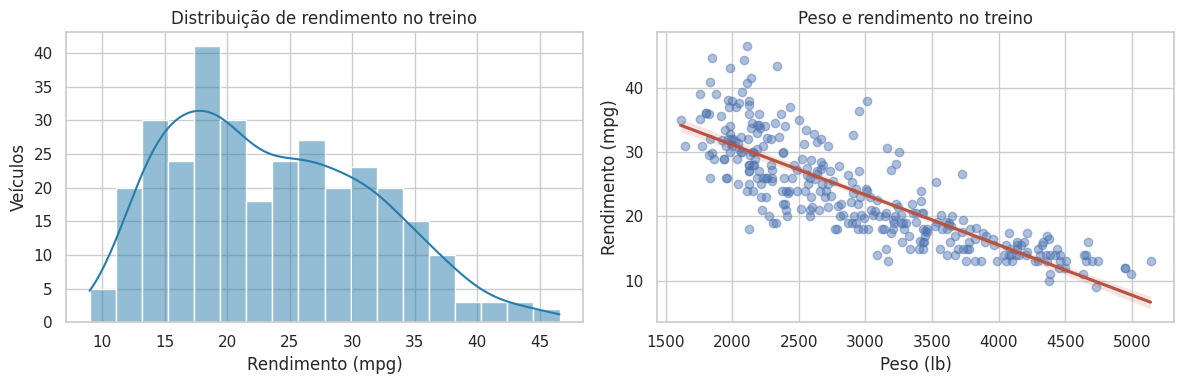

MPG no treino: média 23.61; mediana 22.45.
Registros sinalizados pelo critério 1,5 × IQR: 0.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eda, x="mpg", bins=18, kde=True, ax=axes[0], color="#267DAB")
axes[0].set(title="Distribuição de rendimento no treino", xlabel="Rendimento (mpg)", ylabel="Veículos")
sns.regplot(eda, x="weight", y="mpg", ax=axes[1], scatter_kws={"alpha":0.45}, line_kws={"color":"#B85342"})
axes[1].set(title="Peso e rendimento no treino", xlabel="Peso (lb)", ylabel="Rendimento (mpg)")
plt.tight_layout(); plt.show()
q1, q3 = y_train.quantile([0.25, 0.75]); iqr = q3-q1
extremos = (y_train < q1-1.5*iqr) | (y_train > q3+1.5*iqr)
print(f"MPG no treino: média {y_train.mean():.2f}; mediana {y_train.median():.2f}.")
print(f"Registros sinalizados pelo critério 1,5 × IQR: {extremos.sum()}.")
if extremos.any():
    display(df.loc[y_train[extremos].index, ["name", "model_year", "mpg", "weight"]])

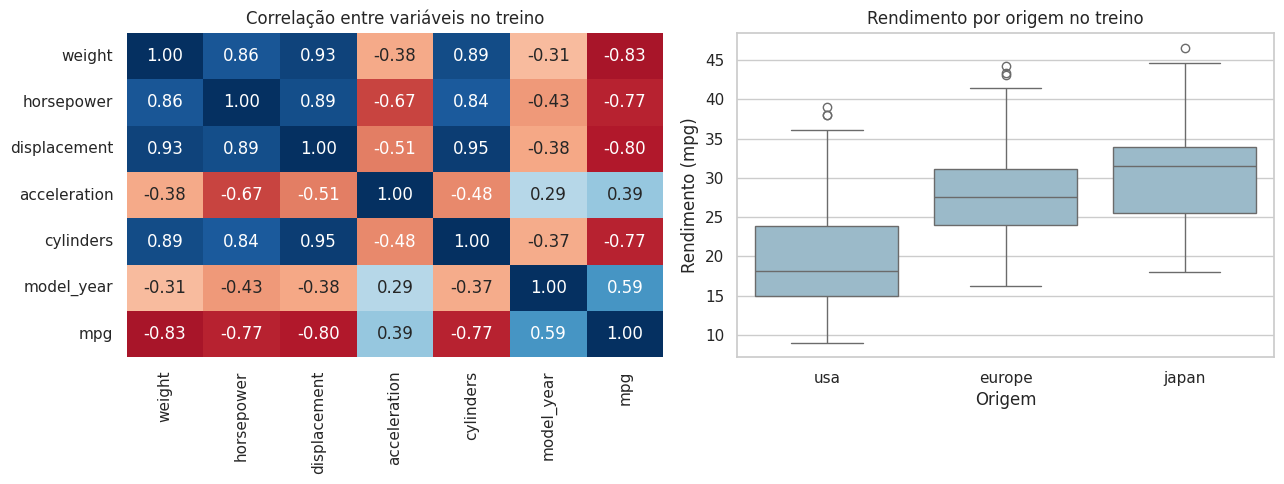

,n,media,mediana
origin,,,
europe,56,28.257,27.600
japan,66,30.335,31.550
usa,196,20.015,18.150


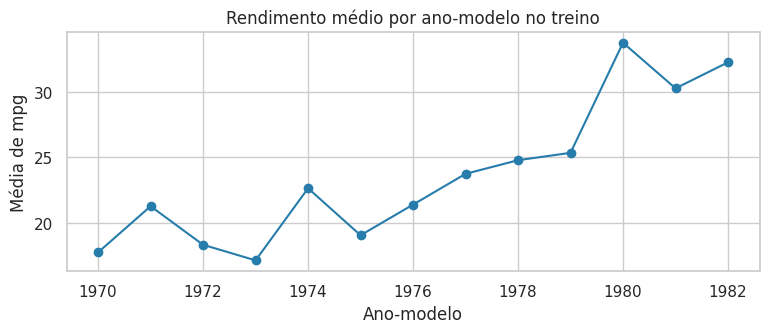

**Leitura dos resultados:** a correlação entre peso e MPG é -0.83, indicando associação inversa. Para ano-modelo e MPG, é 0.59. As diferenças entre origens também refletem diferenças no perfil dos veículos; não isolam um efeito causal da origem.

In [ ]:
corr = eda[numericas + ["mpg"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Correlação entre variáveis no treino")
sns.boxplot(eda, x="origin", y="mpg", order=["usa","europe","japan"], color="#94BCD0", ax=axes[1])
axes[1].set(title="Rendimento por origem no treino", xlabel="Origem", ylabel="Rendimento (mpg)")
plt.tight_layout(); plt.show()
display(eda.groupby("origin")["mpg"].agg(n="count", media="mean", mediana="median"))
anual = eda.groupby("model_year")["mpg"].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(anual.index+1900, anual.values, marker="o", color="#267DAB")
ax.set(title="Rendimento médio por ano-modelo no treino", xlabel="Ano-modelo", ylabel="Média de mpg")
plt.tight_layout(); plt.show()
display(Markdown(f"**Leitura dos resultados:** a correlação entre peso e MPG é {corr.loc['weight','mpg']:.2f}, indicando associação inversa. Para ano-modelo e MPG, é {corr.loc['model_year','mpg']:.2f}. As diferenças entre origens também refletem diferenças no perfil dos veículos; não isolam um efeito causal da origem."))

## 4. Modelos e critério de comparação
Comparamos uma previsão constante pela média, regressão simples, múltipla e polinomial, além de polinômios com Ridge. O grau 3 sem regularização permite observar o risco de sobreajuste.

**Critério principal:** menor MAE médio em validação cruzada com cinco partições do treino. MAE é a média dos erros absolutos em MPG. Também mostramos RMSE, que dá maior peso a erros grandes, e R², que compara os erros quadráticos à variação do alvo. R² não é porcentagem de acertos.

Todos usam as mesmas partições. O teste fica fora da busca por grau e `alpha`. Os resultados de validação usados para escolher os hiperparâmetros podem ser otimistas; a avaliação de teste é relatada separadamente.

In [ ]:
def criar_pipeline(grau=1, alpha=None, simples=False):
    colunas = ["weight"] if simples else numericas
    etapas = [("imputar", SimpleImputer(strategy="median")), ("padronizar", StandardScaler())]
    if grau > 1:
        etapas += [("polinomios", PolynomialFeatures(degree=grau, include_bias=False)),
                   ("padronizar_termos", StandardScaler())]
    transformadores = [("num", Pipeline(etapas), colunas)]
    if not simples:
        transformadores.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), ["origin"]))
    regressor = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return Pipeline([("preparar", ColumnTransformer(transformadores)), ("reg", regressor)])

modelos = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Linear simples (peso)": criar_pipeline(simples=True),
    "Linear múltipla": criar_pipeline(),
    "Polinomial grau 2": criar_pipeline(grau=2),
    "Polinomial grau 3": criar_pipeline(grau=3),
}
buscas = {}
for grau in [2, 3]:
    busca = GridSearchCV(criar_pipeline(grau=grau, alpha=1),
                         {"reg__alpha": np.logspace(-3, 3, 13)},
                         scoring="neg_mean_absolute_error", cv=cv, return_train_score=True)
    busca.fit(X_train, y_train)
    nome = f"Ridge polinomial grau {grau}"
    modelos[nome] = busca.best_estimator_
    buscas[nome] = busca
    print(f"{nome}: alpha selecionado = {busca.best_params_['reg__alpha']:g}")

Ridge polinomial grau 2: alpha selecionado = 10
Ridge polinomial grau 3: alpha selecionado = 10


**Por que padronizar?** Ridge penaliza a magnitude dos coeficientes, que depende das escalas. Padronizamos as variáveis numéricas e, nos modelos polinomiais, os termos gerados. Os indicadores de origem permanecem binários. A expansão polinomial é aplicada apenas às variáveis numéricas.

**O que faz o alpha?** Controla a intensidade da penalização do Ridge: valores maiores tendem a reduzir mais os coeficientes. A escolha é feita pela validação, não pelo resultado de teste.

,MAE treino,MAE CV,DP MAE CV,RMSE CV,R² CV
Modelo,,,,,
Ridge polinomial grau 3,1.739,2.034,0.122,2.837,0.868
Ridge polinomial grau 2,1.956,2.138,0.087,2.988,0.854
Polinomial grau 2,1.918,2.229,0.169,3.091,0.844
Linear múltipla,2.595,2.683,0.179,3.478,0.803
Polinomial grau 3,1.478,2.826,0.561,5.451,0.363
Linear simples (peso),3.352,3.412,0.219,4.493,0.669
Baseline (média),6.681,6.702,0.505,7.923,-0.017


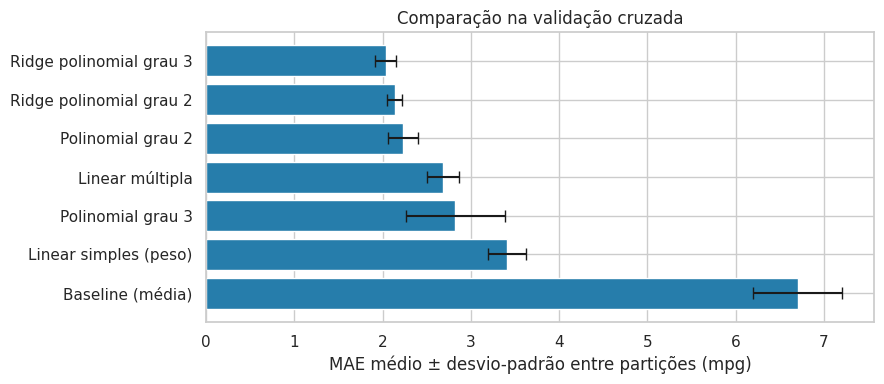

**Modelo selecionado antes da avaliação de teste:** Ridge polinomial grau 3, pelo menor MAE médio de validação (2.034 mpg). O desvio-padrão descreve a oscilação entre as cinco partições, não um intervalo de confiança.

**Sobreajuste:** no grau 3 sem regularização, o MAE de treino é 1.48, enquanto o de validação é 2.83 mpg. Essa diferença mostra por que não escolhemos o modelo apenas pelo ajuste ao treino.

In [ ]:
linhas = []
for nome, modelo in modelos.items():
    notas = cross_validate(modelo, X_train, y_train, cv=cv, return_train_score=True,
                           scoring={"mae":"neg_mean_absolute_error", "rmse":"neg_root_mean_squared_error", "r2":"r2"})
    linhas.append({"Modelo":nome, "MAE treino":-notas["train_mae"].mean(),
                   "MAE CV":-notas["test_mae"].mean(), "DP MAE CV":notas["test_mae"].std(ddof=1),
                   "RMSE CV":-notas["test_rmse"].mean(), "R² CV":notas["test_r2"].mean()})
comparacao = pd.DataFrame(linhas).set_index("Modelo").sort_values("MAE CV")
display(comparacao)
fig, ax = plt.subplots(figsize=(9, 4))
plot = comparacao.sort_values("MAE CV", ascending=False)
ax.barh(plot.index, plot["MAE CV"], xerr=plot["DP MAE CV"], capsize=4, color="#267DAB")
ax.set(title="Comparação na validação cruzada", xlabel="MAE médio ± desvio-padrão entre partições (mpg)")
plt.tight_layout(); plt.show()
nome_escolhido = comparacao.index[0]
modelo_final = modelos[nome_escolhido]
display(Markdown(f"**Modelo selecionado antes da avaliação de teste:** {nome_escolhido}, pelo menor MAE médio de validação ({comparacao.iloc[0]['MAE CV']:.3f} mpg). O desvio-padrão descreve a oscilação entre as cinco partições, não um intervalo de confiança."))
g3 = comparacao.loc["Polinomial grau 3"]
display(Markdown(f"**Sobreajuste:** no grau 3 sem regularização, o MAE de treino é {g3['MAE treino']:.2f}, enquanto o de validação é {g3['MAE CV']:.2f} mpg. Essa diferença mostra por que não escolhemos o modelo apenas pelo ajuste ao treino."))

## 5. Interpretação da regressão múltipla
Usamos o modelo múltiplo para discutir os coeficientes. Nas variáveis numéricas, cada coeficiente corresponde a um aumento de um desvio-padrão do treino, mantendo os demais preditores constantes. Para origem, a comparação é com a categoria de referência. Não interpretamos esses coeficientes como efeitos causais.

In [ ]:
multipla = modelos["Linear múltipla"].fit(X_train, y_train)
prep = multipla.named_steps["preparar"]
nomes = prep.get_feature_names_out()
coef = pd.Series(multipla.named_steps["reg"].coef_, index=[s.split("__",1)[1] for s in nomes], name="Coeficiente")
display(coef.to_frame().sort_values("Coeficiente"))
referencia = prep.named_transformers_["cat"].categories_[0][0]
print("Origem de referência:", referencia)
display(Markdown(f"No modelo múltiplo, o coeficiente de peso é {coef['weight']:.2f} mpg por desvio-padrão e o de ano-modelo é {coef['model_year']:.2f}. Preditores como peso, cilindrada e potência compartilham informação; isso pode alterar sinais e magnitudes em relação às correlações isoladas. Por isso, não usamos apenas o tamanho dos coeficientes como ranking definitivo de importância."))

,Coeficiente
weight,-5.912
origin_usa,-2.948
horsepower,-0.545
cylinders,-0.279
origin_japan,-0.274
acceleration,0.186
displacement,2.036
model_year,2.971


Origem de referência: europe


No modelo múltiplo, o coeficiente de peso é -5.91 mpg por desvio-padrão e o de ano-modelo é 2.97. Preditores como peso, cilindrada e potência compartilham informação; isso pode alterar sinais e magnitudes em relação às correlações isoladas. Por isso, não usamos apenas o tamanho dos coeficientes como ranking definitivo de importância.

## 6. Avaliação final e análise dos erros
Após a seleção pela validação, avaliamos o modelo escolhido no teste. O baseline aparece como referência. Não usamos esta comparação para trocar o modelo selecionado.

,MAE (mpg),MSE (mpg²),RMSE (mpg),R²
Baseline (média),5.955,53.983,7.347,-0.004
Ridge polinomial grau 3,1.678,5.016,2.240,0.907


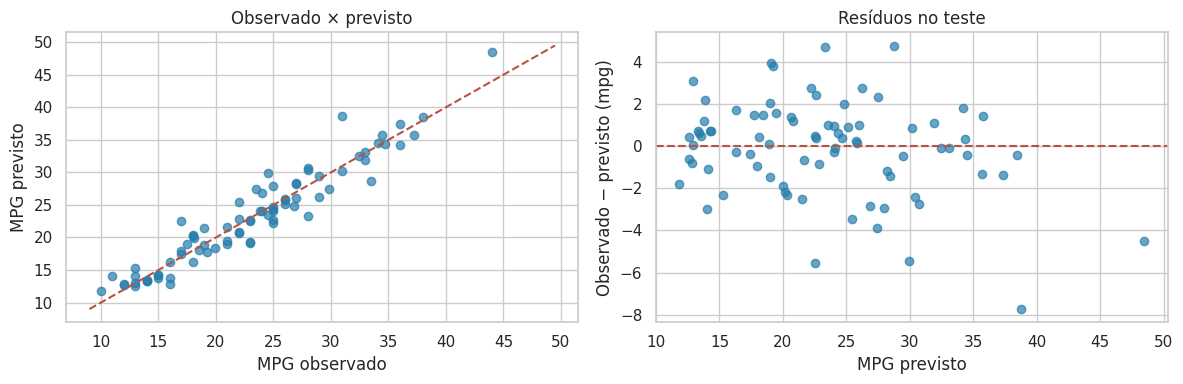

,name,model_year,mpg,previsto,erro absoluto
377,mazda glc custom,82,31.000,38.733,7.733
275,volvo 264gl,78,17.000,22.528,5.528
196,chevrolet woody,76,24.500,29.956,5.456
238,dodge colt m/m,77,33.500,28.739,4.761
30,chevrolet vega 2300,71,28.000,23.323,4.677


**Resultado:** o erro absoluto médio foi 1.68 mpg e o RMSE foi 2.24 mpg. O R² foi 0.907. O maior erro ocorreu em **mazda glc custom**, com 31.00 mpg observado e 38.73 previsto. A base não permite atribuir a causa desse erro a combustível, transmissão ou outra característica não registrada.

In [ ]:
modelo_final.fit(X_train, y_train)
pred = modelo_final.predict(X_test)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
def metricas(real, previsto):
    return {"MAE (mpg)":mean_absolute_error(real, previsto), "MSE (mpg²)":mean_squared_error(real, previsto),
            "RMSE (mpg)":np.sqrt(mean_squared_error(real, previsto)), "R²":r2_score(real, previsto)}
resultado = pd.DataFrame([metricas(y_test, baseline.predict(X_test)), metricas(y_test, pred)],
                         index=["Baseline (média)", nome_escolhido])
display(resultado)
residuos = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
limites = [min(y_test.min(), pred.min())-1, max(y_test.max(), pred.max())+1]
axes[0].scatter(y_test, pred, alpha=0.7, color="#267DAB")
axes[0].plot(limites, limites, "--", color="#B85342")
axes[0].set(title="Observado × previsto", xlabel="MPG observado", ylabel="MPG previsto")
axes[1].scatter(pred, residuos, alpha=0.7, color="#267DAB")
axes[1].axhline(0, linestyle="--", color="#B85342")
axes[1].set(title="Resíduos no teste", xlabel="MPG previsto", ylabel="Observado − previsto (mpg)")
plt.tight_layout(); plt.show()
erros = df.loc[X_test.index, ["name", "model_year", "mpg"]].copy()
erros["previsto"] = pred
erros["erro absoluto"] = np.abs(residuos)
display(erros.nlargest(5, "erro absoluto"))
m = resultado.loc[nome_escolhido]
pior = erros.loc[erros["erro absoluto"].idxmax()]
display(Markdown(f"**Resultado:** o erro absoluto médio foi {m['MAE (mpg)']:.2f} mpg e o RMSE foi {m['RMSE (mpg)']:.2f} mpg. O R² foi {m['R²']:.3f}. O maior erro ocorreu em **{pior['name']}**, com {pior['mpg']:.2f} mpg observado e {pior['previsto']:.2f} previsto. A base não permite atribuir a causa desse erro a combustível, transmissão ou outra característica não registrada."))

## 7. Conclusões e limitações
O peso apresenta associação inversa com MPG, e o ano-modelo também contribui para a previsão. A comparação entre modelos permite verificar se termos polinomiais e Ridge melhoram a generalização. A seleção e as métricas abaixo são atualizadas pela execução, evitando divergências entre texto e tabelas.

In [ ]:
ganho = 100*(1-resultado.loc[nome_escolhido, "MAE (mpg)"]/resultado.loc["Baseline (média)", "MAE (mpg)"])
display(Markdown(f"**Conclusão da modelagem:** {nome_escolhido} teve o menor MAE médio na validação. No teste, seu MAE foi {m['MAE (mpg)']:.2f} mpg, uma redução de {ganho:.1f}% em relação ao baseline. O ganho mostra utilidade preditiva para esta divisão da base, sem garantir o mesmo desempenho em outra população de veículos."))

**Conclusão da modelagem:** Ridge polinomial grau 3 teve o menor MAE médio na validação. No teste, seu MAE foi 1.68 mpg, uma redução de 71.8% em relação ao baseline. O ganho mostra utilidade preditiva para esta divisão da base, sem garantir o mesmo desempenho em outra população de veículos.

**Limitações**

- A base representa veículos de 1970 a 1982; não sustenta previsões para automóveis modernos sem novos dados.
- A amostra é pequena e tem mais veículos dos EUA. Algumas categorias possuem poucos exemplos.
- Faltam atributos como combustível, transmissão e aerodinâmica. A imputação de potência é uma aproximação.
- A divisão aleatória avalia veículos da mesma base; não simula prever anos futuros nem garante independência entre modelos de carros semelhantes.
- A validação foi usada para ajustar e comparar modelos; pequenas diferenças de desempenho não comprovam superioridade estatística.
- Esta é uma revisão de um trabalho cujas versões anteriores já consultaram o mesmo teste. O fluxo atual separa seleção e avaliação, mas esse teste não é uma validação externa completamente inédita.
- As relações observadas são associativas. Não permitem concluir que alterar isoladamente uma característica produziria a mudança prevista.

